# Tile Feature Embedding and Logistic Regression Training

**Author: Fabien Bertillot**  

---

## 1. Introduction

This notebook implements a two‐stage pipeline for colorectal cancer image analysis:

1. **U-Net inference** Generate tumor architecture feature embedding for image tiles using a pretrained UNet. Those image tiles were each manually annotated by tumor architecture type (e.g., glandular, fragmented). The UNet model was trained using the U-Net (2D) multilabel notebook from https://github.com/HenriquesLab/ZeroCostDL4Mic/wiki#contributors
2. **t-SNE projection** Reduce the dimensionality of the extracted embeddings using t-SNE to visualize the underlying structure of the tumor architecture features.
3. **Logistic regression** Train a logistic regression model on the spatial features of the manually annotated tiles to train the final tumor architecture types (e.g., glandular vs. fragmented).
4. **Tissue-Level Probability Mapping** Visualize the predicted class probabilities spatially, overlaid on the pan-EPI (tumor) staining to interpret regional tumor architecture across the tissue section.

---

## 2. Prerequisites

- **Python 3.9+**, with packages:
  - `tensorflow` / `keras` (for UNet model)
  - `numpy`, `pandas`
  - `scikit‐image` (for mask processing)
  - `scikit‐learn` (for logistic regression)
- Access to:
  - **Pretrained UNet weights** (`.h5` file)
  - **Directory of input images** (`.tif`)
  - **CSV of labels** 

---

## 3. Notebook Structure

1. **Load Dependencies**  

2. **Check GPU Access**  

3. **Load U-Net model**
   - Load U-Net model and extract the bottleneck layer of the network
4. **U-Net Inference**  
   - Load annotations of each tile
   - Tile‐based embedding prediction function  
5. **t-SNE projection**  
   - Compute first 2 t-SNE components
   - Plot first 2 t-SNE components colored by architecture labels
6. **Logistic Regression Training**  
   - Model fitting and cross‐validation  
   - Performance metrics (accuracy, AUC)
7. **Results & Saving**  
   - Save trained model  
   - Export evaluation report (`.csv` and plots)

---


## 1) Load Dependencies

In [1]:
import os

from UNet_utils import *
import tensorflow as tf
from tensorflow.keras.models import Model, load_model
from tensorflow.keras import backend as keras

import numpy as np
import pandas as pd

from pathlib import PurePath


## 2) Check GPU Access

In [3]:
import tensorflow as tf
print(tf.__version__)
print(tf.config.list_physical_devices('GPU'))

2.17.0
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


I0000 00:00:1743693247.009849    3585 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1743693247.058796    3585 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1743693247.058884    3585 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.


## 3) Load U-Net model 

In [4]:
model_path = r''
unet = load_model(model_path, custom_objects={'_weighted_binary_crossentropy': weighted_binary_crossentropy(np.ones(2))})
Input_size = unet.input_shape[1:3]
print('Model input size: '+str(Input_size[0])+'x'+str(Input_size[1]))

I0000 00:00:1743693281.133713    3585 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1743693281.133785    3585 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1743693281.133805    3585 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1743693282.436368    3585 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1743693282.436430    3585 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2025-04-03

Model input size: 320x320


## 4) U-Net Inference

In [ ]:
import pandas as pd
TILE_FOLDER = r''
PATH_TRAIN_LABELS = r''

df = pd.read_csv(PATH_TRAIN_LABELS)
df['label'] = df['label'].replace('Odd', 'Edge')

In [6]:
model = unet
feature_layer = model.get_layer('conv2d_23').output

In [ ]:
import numpy as np
from tensorflow.keras.layers import GlobalAveragePooling2D
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns

predictions = []
labels = []

for index, row in df.iterrows():
    image_name = row['image_name']
    image_path = f'{TILE_FOLDER}/{image_name}'
    image_raw = io.imread(image_path, as_gray=True)

    label = row['label']
    
    # Extract features for the image
    features = extract_embedding(model, feature_layer, image_raw)
    pooled_features = GlobalAveragePooling2D()(features[0])
    
    # # Append the mean feature vector to the list
    predictions.append(pooled_features)
    labels.append(label)
    
    if index % 100 == 0:
        print(f'{index}/{len(df)}')


## 5) t-SNE Projection

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import seaborn as sns
import matplotlib.pyplot as plt

feature_matrix = np.vstack(predictions)

# Standardize the data
scaler = StandardScaler()
feature_matrix_scaled = scaler.fit_transform(feature_matrix)

# Perform t-SNE 
tsne = TSNE(n_components=2, random_state=42)
tsne_results = tsne.fit_transform(feature_matrix_scaled)

df['TSNE1'] = tsne_results[:, 0]
df['TSNE2'] = tsne_results[:, 1]


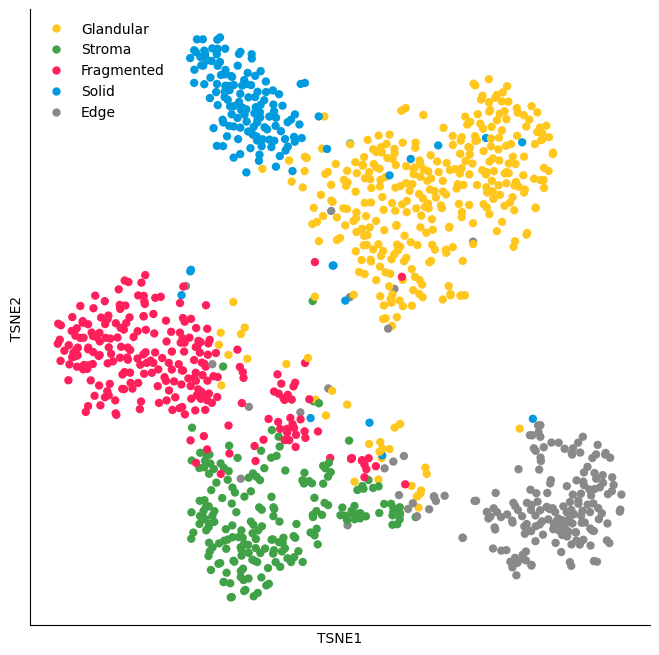

In [54]:
palette = ['#FFC61E', '#41A147', '#FF1F5B', '#009ADE', '#898989']

plt.figure(figsize=(8, 8))
ax = sns.scatterplot(
    x='TSNE1', y='TSNE2',
    hue='label',
    palette=palette,
    data=df,
    legend="full",
    alpha=1,
    linewidth=0  # Remove linewidth of points
)

# Remove x and y ticks
ax.set_xticks([])
ax.set_yticks([])

# Remove the legend frame
ax.legend(frameon=False)

sns.despine()

out_path = '/mnt/c/Users/fbertil/CRC Figures/architecture_analysis/figures/training/architecture_tsne_unet3.pdf'
plt.savefig(out_path, format='pdf', bbox_inches='tight', dpi=300)


## 6) Logistic Regression Training

Fold 1/5
Fold 2/5


/home/fbertil/miniconda3/envs/tf-wsl2/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/home/fbertil/miniconda3/envs/tf-wsl2/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Fold 3/5
Fold 4/5


/home/fbertil/miniconda3/envs/tf-wsl2/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/home/fbertil/miniconda3/envs/tf-wsl2/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Fold 5/5


/home/fbertil/miniconda3/envs/tf-wsl2/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


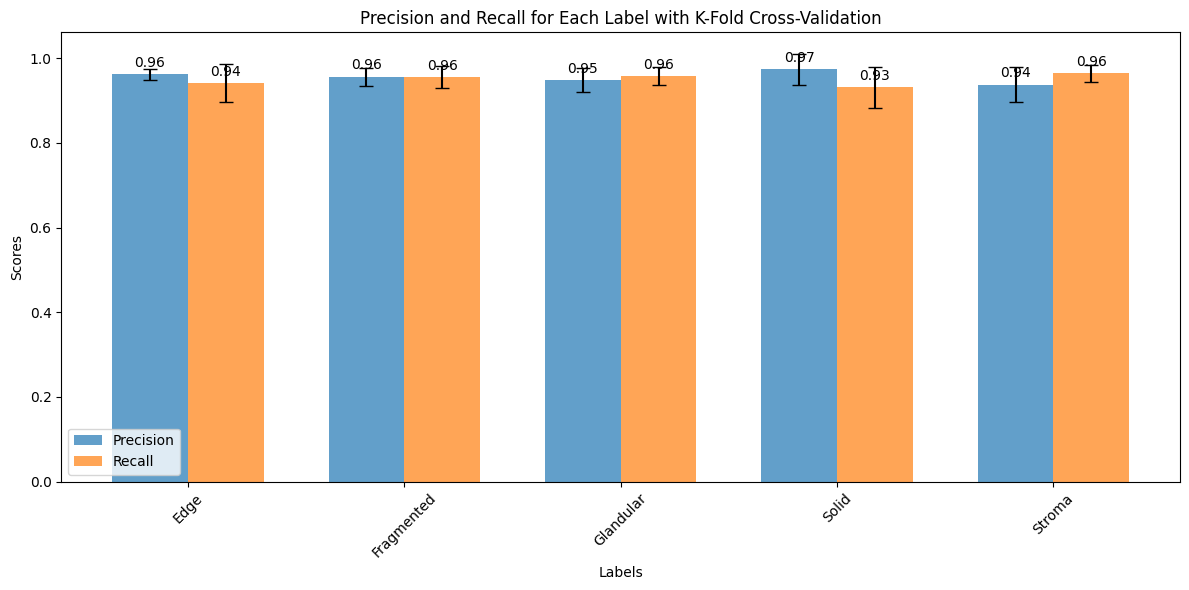

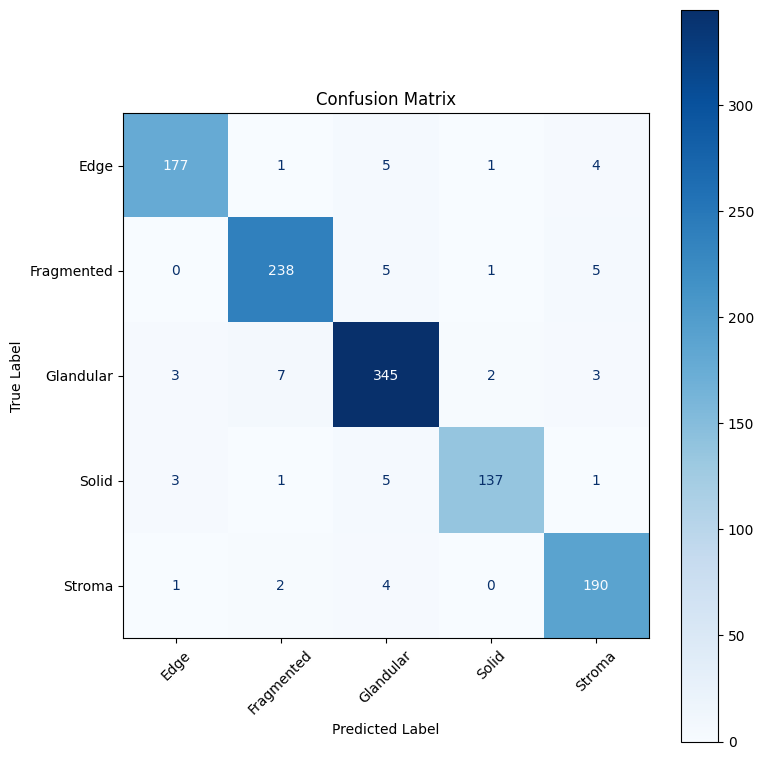

Model saved to /mnt/c/Users/fbertil/CRC_TMA_tile_classification/predictive_models/logistic_regression_unet3/logistic_regression_model_unet3.joblib
Scaler saved to /mnt/c/Users/fbertil/CRC_TMA_tile_classification/predictive_models/logistic_regression_unet3/scaler.joblib
Label encoder saved to /mnt/c/Users/fbertil/CRC_TMA_tile_classification/predictive_models/logistic_regression_unet3/label_encoder.joblib


/home/fbertil/miniconda3/envs/tf-wsl2/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


In [16]:
# -- Logistic Regression --

import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder, StandardScaler
import matplotlib.pyplot as plt

# Assuming df is your DataFrame with 'features' and 'label' columns
# and 'predictions' is a list or array of feature vectors

# Step 1: Extract features and labels
X = np.vstack(predictions)
y = df['label'].values

# Step 2: Encode labels and standardize features
le = LabelEncoder()
y_encoded = le.fit_transform(y)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 3: Initialize K-fold cross-validation
k = 5  # Number of folds
skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

# Initialize dictionaries to collect precision and recall
labels = le.classes_
precision_scores = {label: [] for label in labels}
recall_scores = {label: [] for label in labels}

# Initialize lists to collect all true labels and predictions
all_y_test = []
all_y_pred = []

# Step 4: Perform cross-validation
for fold, (train_index, test_index) in enumerate(skf.split(X_scaled, y_encoded)):
    print(f"Fold {fold + 1}/{k}")
    X_train, X_test = X_scaled[train_index], X_scaled[test_index]
    y_train, y_test = y_encoded[train_index], y_encoded[test_index]
    
    # Initialize the LogisticRegression model
    clf = LogisticRegression(
        solver='lbfgs',
        multi_class='multinomial',
        max_iter=1000,
        random_state=12
    )
    clf.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = clf.predict(X_test)
    
    # Evaluate the classifier
    report = classification_report(
        y_test, y_pred, target_names=labels, output_dict=True
    )
    # Collect predictions and true labels
    all_y_test.extend(y_test)
    all_y_pred.extend(y_pred)

    # Collect precision and recall for each label
    for label in labels:
        precision = report[label]['precision']
        recall = report[label]['recall']
        precision_scores[label].append(precision)
        recall_scores[label].append(recall)

# Step 5: Compute mean and standard deviation for precision and recall
precision_means = []
precision_stds = []
recall_means = []
recall_stds = []

for label in labels:
    p_scores = precision_scores[label]
    r_scores = recall_scores[label]
    precision_means.append(np.mean(p_scores))
    precision_stds.append(np.std(p_scores))
    recall_means.append(np.mean(r_scores))
    recall_stds.append(np.std(r_scores))

# Create a DataFrame for plotting
metrics_df = pd.DataFrame({
    'Label': labels,
    'Precision Mean': precision_means,
    'Precision Std': precision_stds,
    'Recall Mean': recall_means,
    'Recall Std': recall_stds
})


# Step 7: Compute and plot the confusion matrix
# Convert lists to arrays
all_y_test = np.array(all_y_test)
all_y_pred = np.array(all_y_pred)

# Compute the confusion matrix
cm = confusion_matrix(all_y_test, all_y_pred)

# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

from sklearn.linear_model import LogisticRegression
import joblib  # For saving the model

# Retrain the model on the full dataset
final_model = LogisticRegression(
    solver='lbfgs',
    multi_class='multinomial',
    max_iter=1000,
    random_state=12
)
final_model.fit(X_scaled, y_encoded)

# # Save the model to a file
# model_filename = r'logistic_regression_model.joblib'
# joblib.dump(final_model, model_filename)
# print(f"Model saved to {model_filename}")

# # Save the scaler
# scaler_filename = r'scaler.joblib'
# joblib.dump(scaler, scaler_filename)
# print(f"Scaler saved to {scaler_filename}")

# # Save the label encoder
# le_filename = 'label_encoder.joblib'
# joblib.dump(le, le_filename)
# print(f"Label encoder saved to {le_filename}")


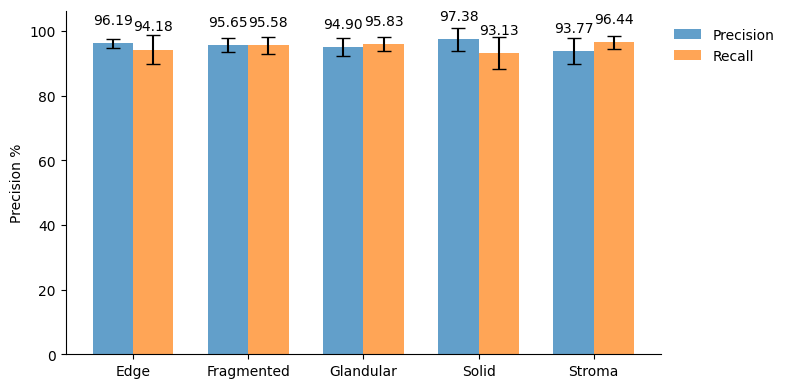

In [45]:
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
# Step 6: Plot precision and recall with error bars
plt.figure(figsize=(8, 4))
bar_width = 0.35
index = np.arange(len(metrics_df))

# Plot Precision
precision_bars = plt.bar(
    index,
    metrics_df['Precision Mean']*100,
    bar_width,
    yerr=metrics_df['Precision Std']*100,
    capsize=5,
    label='Precision',
    alpha=0.7
)

# Plot Recall
recall_bars = plt.bar(
    index + bar_width,
    metrics_df['Recall Mean']*100,
    bar_width,
    yerr=metrics_df['Recall Std']*100,
    capsize=5,
    label='Recall',
    alpha=0.7
)

# Annotate Precision bars
for bar in precision_bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 5,
        f'{height:.2f}',
        ha='center',
        va='bottom',
        fontsize=10,
        color='black'
    )

# Annotate Recall bars
for bar in recall_bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 5,
        f'{height:.2f}',
        ha='center',
        va='bottom',
        fontsize=10,
        color='black'
    )


# plt.xlabel('Labels')
plt.ylabel('Precision %')
# plt.title('Precision and Recall for Each Label with K-Fold Cross-Validation')
plt.xticks(index + bar_width / 2, metrics_df['Label'], rotation=0)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.9), frameon=False)

sns.despine()
plt.tight_layout()
# plt.show()


out_path = '/mnt/c/Users/fbertil/CRC Figures/architecture_analysis/figures/training/architecture_kfold_unet3.pdf'
# out_path = r'C:\Users\fbertil\CRC Figures\architecture_analysis\figures\test.pdf'
plt.savefig(out_path, format='pdf', bbox_inches='tight', dpi=300)

## 7) Tissue-Level Probability Mapping

In [32]:
from tifffile import imread
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D
import matplotlib.pyplot as plt
from typing import List, Tuple, Callable, Optional, Union, Dict, Literal, Any
import gc

# label_mapping = dict(zip(le.transform(le.classes_), le.classes_))


def generate_overlapping_tiles(image_shape: Tuple[int, int],
                               tile_size: int = 224,
                               stride: int = 112) -> List[Tuple[int, int]]:
    coords = []
    h, w = image_shape
    x_points = list(range(0, w - tile_size + 1, stride))
    y_points = list(range(0, h - tile_size + 1, stride))

    if x_points[-1] + tile_size < w:
        x_points.append(w - tile_size)
    if y_points[-1] + tile_size < h:
        y_points.append(h - tile_size)

    for y in y_points:
        for x in x_points:
            coords.append((x, y))

    return coords

def initialize_probability_and_count_maps(image_shape: Tuple[int, int]) -> Tuple[np.ndarray, np.ndarray]:
    h, w = image_shape
    probability_map = np.zeros((h, w), dtype=np.float32)
    count_map = np.zeros((h, w), dtype=np.float32)
    return probability_map, count_map

def process_tiles_and_update_maps(image: np.ndarray,
                                  tile_coords: List[Tuple[int, int]],
                                  tile_size: int,
                                  label: int,
                                  feature_extractor_model,
                                  classifier_model,
                                  scaler,
                                  probability_map: np.ndarray,
                                  count_map: np.ndarray):
    index_of_label_1 = np.where(classifier_model.classes_ == label)[0][0]  # Adjust '1' to your actual label

    for idx, (x, y) in enumerate(tile_coords):
        # Extract the tile
        tile = image[y:y + tile_size, x:x + tile_size]
        
        features = extract_features_as_tiles(tile)
        pooled_features = GlobalAveragePooling2D()(features[0]).numpy()
        features_scaled = scaler.transform(pooled_features)
        
        # Predict probability
        y_pred_prob = classifier_model.predict_proba(features_scaled)
        probability_label_1 = y_pred_prob[0][index_of_label_1]
        
        # Update the probability map and count map
        probability_map[y:y + tile_size, x:x + tile_size] += probability_label_1
        count_map[y:y + tile_size, x:x + tile_size] += 1
        
        if idx % 100 == 0:
            print(f"Processed {idx + 1}/{len(tile_coords)} tiles")

    return probability_map, count_map

def process_tiles_and_collect_predictions(image: np.ndarray,
                                          tile_coords: List[Tuple[int, int]],
                                          
                                          tile_size: int,
                                          feature_extractor_model,
                                          classifier_model,
                                          scaler,
                                          batch_size: int = 8) -> pd.DataFrame:
    tile_predictions = []
    # Get the mapping from encoded labels to their indices
    label_indices = {label: idx for idx, label in enumerate(classifier_model.classes_)}

    num_tiles = len(tile_coords)
    for i in range(0, num_tiles, batch_size):
        batch_coords = tile_coords[i:i + batch_size]

        for x, y in batch_coords:

            tile = image[y:y + tile_size, x:x + tile_size]

            features = extract_features_as_tiles(tile)
            pooled_features = GlobalAveragePooling2D()(features[0]).numpy()
            features_scaled = scaler.transform(pooled_features)
            y_pred_prob = classifier_model.predict_proba(features_scaled)
            epsilon = 1e-12
            y_pred_prob_adjusted = y_pred_prob + epsilon
            entropy_values = -np.sum(y_pred_prob_adjusted * np.log2(y_pred_prob_adjusted), axis=1)

            prob_dict = {'x': x, 'y': y, 'shannon_entropy':entropy_values[0]}
            
            for label, prob in zip(classifier_model.classes_, y_pred_prob[0]):
                prob_dict[f'prob_{label_mapping[label]}'] = prob

            tile_predictions.append(prob_dict)

            gc.collect()


        if i % (batch_size * 10) == 0:
            print(f"Processed {i + len(batch_coords)}/{num_tiles} tiles")

    df_pred = pd.DataFrame(tile_predictions)

    return df_pred

def process_tiles_and_collect_embeddings(image: np.ndarray,
                                          tile_coords: List[Tuple[int, int]],
                                          tile_size: int,
                                          feature_extractor_model,
                                          batch_size: int = 8) -> pd.DataFrame:
    tile_embeddings = {}
    # Get the mapping from encoded labels to their indices

    num_tiles = len(tile_coords)
    k= 0
    for i in range(0, num_tiles, batch_size):
        batch_coords = tile_coords[i:i + batch_size]

        for x, y in batch_coords:

            tile = image[y:y + tile_size, x:x + tile_size]

            # features = extract_features_as_tiles(tile, feature_extractor)
            # pooled_features = GlobalAveragePooling2D()(features[0]).numpy()

            features = extract_features_as_tiles(tile)
            pooled_features = GlobalAveragePooling2D()(features[0]).numpy()

            prob_dict = {'x': x, 'y': y}
            prob_dict["embedding"] = pooled_features[0].tolist()

            tile_embeddings[k] = prob_dict

            gc.collect()
            k+=1

        if i % (batch_size * 10) == 0:
            print(f"Processed {i + len(batch_coords)}/{num_tiles} tiles")

    # df_pred = pd.DataFrame(tile_predictions)

    return tile_embeddings

In [47]:
import joblib

IMAGE_DIR = r'/mnt/e/CRC_DAPI'
IMAGE_NAME = 'reg_2a_K-15.tif'
TILE_SIZE = 448
STRIDE = 448

save_dir = r'/mnt/c/Users/fbertil/CRC_TMA_tile_classification/predictive_models/logistic_regression_unet3'
# Define filenames with relative paths
model_path = os.path.join(save_dir, 'model.joblib')
scaler_path = os.path.join(save_dir, 'scaler.joblib')
label_encoder_path = os.path.join(save_dir, 'label_encoder.joblib')

# Load the Logistic Regression model
clf_loaded = joblib.load(model_path)
print("Logistic Regression model loaded successfully.")

# Load the StandardScaler
scaler_loaded = joblib.load(scaler_path)
print("StandardScaler loaded successfully.")

# Load the LabelEncoder
le_loaded = joblib.load(label_encoder_path)
print("LabelEncoder loaded successfully.")

         
image_path = f'{IMAGE_DIR}/{IMAGE_NAME}'

# mask = imread(mask_path) 
image = imread(image_path)[1,::]

h, w = image.shape

# Generate overlapping tile coordinates
tile_coords = generate_overlapping_tiles((h, w), TILE_SIZE, STRIDE)
probability_map_frag, count_map_frag = initialize_probability_and_count_maps(image_shape=image.shape)
probability_map_gland, count_map_gland = initialize_probability_and_count_maps(image_shape=image.shape)
probability_map_solid, count_map_solid = initialize_probability_and_count_maps(image_shape=image.shape)

probability_map_frag, count_map_frag = process_tiles_and_update_maps(image= image,
    tile_coords= tile_coords,
    tile_size= TILE_SIZE,
    label=1,
    feature_extractor_model = unet,
    classifier_model=clf_loaded,
    scaler=scaler_loaded,
    probability_map = probability_map_frag,
    count_map= count_map_frag

    )

probability_map_gland, count_map_gland = process_tiles_and_update_maps(image= image,
    tile_coords= tile_coords,
    tile_size= TILE_SIZE,
    label=2,
    feature_extractor_model = unet,
    classifier_model=clf_loaded,
    scaler=scaler_loaded,
    probability_map = probability_map_gland,
    count_map= count_map_gland

    )

probability_map_solid, count_map_solid = process_tiles_and_update_maps(image= image,
    tile_coords= tile_coords,
    tile_size= TILE_SIZE,
    label=3,
    feature_extractor_model = unet,
    classifier_model=clf_loaded,
    scaler=scaler_loaded,
    probability_map = probability_map_solid,
    count_map= count_map_solid

    )


Logistic Regression model loaded successfully.
StandardScaler loaded successfully.
LabelEncoder loaded successfully.
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
Processed 1/49 tiles
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

In [48]:
label_mapping = dict(zip(le_loaded.transform(le_loaded.classes_), le_loaded.classes_))
label_mapping

{0: 'Edge', 1: 'Fragmented', 2: 'Glandular', 3: 'Solid', 4: 'Stroma'}

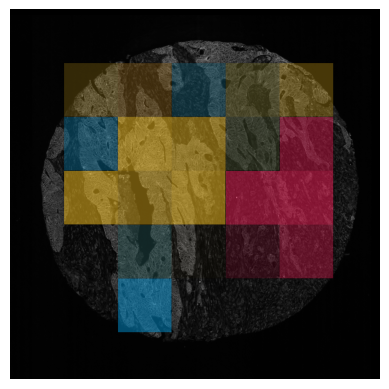

In [58]:
from matplotlib.colors import LinearSegmentedColormap, to_rgba

colors = {
    "Blue": "#009ADE",
    "Yellow": "#FFC61E",
    "Red": "#FF1F5B"
}

# Create colormaps
# colormaps = {name: LinearSegmentedColormap.from_list(name, ["black", color]) for name, color in colors.items()}
colormaps = {
    name: LinearSegmentedColormap.from_list(
        name, 
        [(0, 0, 0, 0), to_rgba(color)]
    )
    for name, color in colors.items()
}
plt.imshow(image, cmap='gray')
plt.imshow(probability_map_frag, cmap=colormaps['Red'],alpha=0.5,vmin=0, vmax=1)
plt.imshow(probability_map_gland, cmap=colormaps['Yellow'],alpha=0.5,vmin=0, vmax=1)
plt.imshow(probability_map_solid, cmap=colormaps['Blue'],alpha=0.5,vmin=0, vmax=1)


plt.axis('off')

out_path = f'/mnt/c/Users/fbertil/CRC Figures/architecture_analysis/figures/training/probabilities_{IMAGE_NAME}'
# out_path = r'C:\Users\fbertil\CRC Figures\architecture_analysis\figures\test.pdf'
plt.savefig(out_path, format='pdf', bbox_inches='tight', dpi=300)

